# 03. Classification - Crop Recommendation

## 1. Mục tiêu

Xây dựng mô hình **Supervised Classification** để dự đoán loại cây trồng dựa trên các đặc trưng về đất và khí hậu.

Các đặc trưng đầu vào gồm:

- `N`: Hàm lượng Nitơ trong đất
- `P`: Hàm lượng Photpho trong đất
- `K`: Hàm lượng Kali trong đất
- `temperature`: Nhiệt độ
- `humidity`: Độ ẩm
- `ph`: Độ pH
- `rainfall`: Lượng mưa

Dữ liệu đầu vào là dữ liệu đã được làm sạch, mã hóa và chia thành tập Train/Test bởi Thành viên 2, được lưu trong thư mục `data/processed/`.

## 2. Mô hình sử dụng

Hai thuật toán được sử dụng để thực nghiệm và so sánh:

1. **Random Forest** – mô hình chính.
2. **Support Vector Machine (SVM)** – mô hình so sánh.
3. **Decision Tree** - mô hình cây quyết định

## 3. Tiêu chí đánh giá

Các mô hình được đánh giá dựa trên:

- Accuracy - Độ chính xác tổng thể
- Precision - Độ chuẩn xác
- Recall - Độ bao phủ
- Confusion Matrix - Ma trận nhầm lẫn
- Thời gian huấn luyện và dự đoán

## 4. Cài đặt và import thư viện

Các thư viện được sử dụng để đọc dữ liệu, xây dựng mô hình Machine Learning, đánh giá kết quả và trực quan hóa kết quả thực nghiệm.

> Lưu ý: Project đã có file `requirements.txt` để quản lý các thư viện cần thiết.

In [1]:
import os      # thư viện tương tác hệ điều hành
import time    # thư viện xử lý tg
import joblib  # thư viện lưu mô hình học máy
import numpy as np   #  thư viện chuyên tính toán số học, mảng đa chiều
import pandas as pd  # thư viện chuyên đọc, xử lý và thao tác dữ liệu dạng bảng 
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore') # Tắt cảnh báo

from sklearn.ensemble import RandomForestClassifier   # mô hình thuật toán phân loại Rừng ngẫu nhiên
from sklearn.svm import SVC   # mô hình thuật toán Máy cực đại véc-tơ hỗ trợ
from sklearn.tree import DecisionTreeClassifier   # mô hình thuật toán Cây quyết định
from sklearn.model_selection import GridSearchCV  # Thư viện dò tham số 
from sklearn.metrics import (
    accuracy_score,  #  Hàm tính tỷ lệ dự đoán chính xác tổng thể.
    precision_score, # Hàm tính độ chuẩn xác (tỷ lệ đoán đúng trên số lần đoán "Có").
    recall_score,    # Hàm tính độ bao phủ (tỷ lệ đoán ra được bao nhiêu phần trăm trên thực tế).
    classification_report,  # Hàm tạo báo cáo tổng hợp các chỉ số trên một cách chi tiết cho từng loại cây.
    confusion_matrix  # Hàm tính toán Ma trận nhầm lẫn để xem mô hình hay nhầm lẫn loại cây nào với nhau.  
)   # công cụ đánh giá mô hình

print("Import thư viện thành công!")

Import thư viện thành công!


## 5. Đọc dữ liệu

Dữ liệu đã được xử lý từ bước Preprocessing và được lưu thành các file:

- `X_train.csv`: tập đặc trưng dùng để huấn luyện.
- `X_test.csv`: tập đặc trưng dùng để kiểm thử.
- `y_train.csv`: nhãn tương ứng với tập Train.
- `y_test.csv`: nhãn tương ứng với tập Test.
- `label_mapping.csv`: bảng ánh xạ giữa mã số và tên loại cây.

Các file được đọc từ thư mục `data/processed/`.

In [2]:
DATA_PATH = "../data/processed/"

X_train = pd.read_csv(DATA_PATH + "X_train.csv")
X_test = pd.read_csv(DATA_PATH + "X_test.csv")

y_train = pd.read_csv(DATA_PATH + "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_PATH + "y_test.csv").squeeze()

mapping_path = DATA_PATH + "label_mapping.csv"

if os.path.exists(mapping_path):
    mapping_df = pd.read_csv(mapping_path)
    mapping_df = mapping_df.sort_values("Mã số")  # sắp xếp tăng dần dựa trên cột mã số
    class_names = mapping_df["Tên cây"].tolist()
else:
    class_names = sorted(            # sắp xếp tăng dần
        np.unique(                   # loại bỏ giá trị trùng lặp
            np.concatenate([         # nối 2 tập giá trị train và test lại
                y_train.values,
                y_test.values
            ])
        )
    )

print("Kích thước dữ liệu:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nCác đặc trưng:")
print(list(X_train.columns))

print("\nSố lớp:", len(class_names))

Kích thước dữ liệu:
X_train: (1760, 7)
X_test : (440, 7)
y_train: (1760,)
y_test : (440,)

Các đặc trưng:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

Số lớp: 22


## 6. Kiểm tra dữ liệu trước khi huấn luyện

Trước khi xây dựng mô hình, kiểm tra dữ liệu đầu vào nhằm đảm bảo tập Train và Test không chứa giá trị thiếu.

Ngoài ra, kiểm tra số lượng đặc trưng và số lượng lớp của bài toán phân loại.

In [3]:
missing_train = X_train.isnull().sum().sum()
missing_test = X_test.isnull().sum().sum()

print("Missing values trong X_train:", missing_train)
print("Missing values trong X_test :", missing_test)

print("Số đặc trưng:", X_train.shape[1])
print("Số lớp:", len(class_names))

if missing_train == 0 and missing_test == 0:
    print("\nDữ liệu không có missing values.")
else:
    print("\nCần kiểm tra và xử lý missing values trước khi huấn luyện.")

Missing values trong X_train: 0
Missing values trong X_test : 0
Số đặc trưng: 7
Số lớp: 22

Dữ liệu không có missing values.


# 7. Random Forest

Random Forest là thuật toán Ensemble Learning kết hợp nhiều Decision Tree để đưa ra dự đoán cuối cùng.

Trong đồ án này, Random Forest được sử dụng làm mô hình chính để dự đoán loại cây trồng dựa trên các đặc trưng về đất và khí hậu.

In [4]:
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)
# 2. Định nghĩa danh sách các tham số muốn máy tính thử nghiệm
rf_params = {
    'n_estimators': [50, 100],  # Thử nghiệm tạo ra rừng có 50 cây và 100 cây
    'max_depth': [None, 10]  # Thử nghiệm độ sâu của nhánh cây (None: mọc tự do, 10 nhánh)
}
# 3. Khởi tạo thuật toán GridSearchCV để máy tự động dò tham số
# cv=3: Thuật toán kiểm định chéo (Cross-Validation). Chia data làm 3 phần để test chéo tránh học vẹt
# scoring='accuracy': Lấy tiêu chí Độ chính xác (Accuracy) làm thước đo để chọn ra bộ tham số giỏi nhất
random_forest = GridSearchCV(rf_base, rf_params, cv=3, scoring='accuracy', n_jobs=-1)

# Huấn luyện
start_time = time.time()
random_forest.fit(X_train, y_train)
rf_train_time = time.time() - start_time   # tính tg học
print(f"Tham số tốt nhất RF: {random_forest.best_params_}")

# Dự đoán
start_time = time.time()
y_pred_rf = random_forest.predict(X_test)   # predict() là hàm y/c mô hình dự đoán => cây gì 
rf_predict_time = time.time() - start_time

print(f"Thời gian train     : {rf_train_time:.4f} giây")
print(f"Thời gian dự đoán   : {rf_predict_time:.4f} giây")

Tham số tốt nhất RF: {'max_depth': None, 'n_estimators': 50}
Thời gian train     : 3.5719 giây
Thời gian dự đoán   : 0.0178 giây


### Nhận xét quá trình huấn luyện Random Forest (GridSearchCV)

Dựa vào kết quả trả về từ quá trình tự động dò tìm tham số (GridSearchCV), ta có thể đánh giá sơ bộ về mô hình như sau:

**1. Bộ tham số tối ưu (Best Parameters):**
- `n_estimators = 50`: Quá trình dò tham số cho thấy một rừng gồm **50 cây quyết định** là đã đủ để mang lại kết quả tốt nhất. Việc sử dụng 50 cây thay vì 100 cây giúp mô hình nhẹ hơn, tiết kiệm tài nguyên bộ nhớ và thời gian tính toán mà không làm giảm độ chính xác.
- `max_depth = None`: Tham số này có nghĩa là các nhánh cây quyết định được phép "mọc tự do" (phân chia liên tục) cho đến khi các lá (nhóm dữ liệu cuối cùng) trở nên hoàn toàn tinh khiết (mỗi lá chỉ chứa 1 loại cây duy nhất) hoặc chứa ít hơn số lượng mẫu tối thiểu. Điều này cho thấy dữ liệu của chúng ta khá phức tạp và mô hình cần đào sâu hết mức có thể để phân loại rạch ròi 22 giống cây trồng.

**2. Hiệu năng thời gian thực thi (Performance Time):**
- **Thời gian huấn luyện (Train time): ~3.48 giây.** Đây là tốc độ huấn luyện rất ấn tượng. Cần lưu ý rằng GridSearchCV phải chia tập dữ liệu ra làm 3 phần (`cv=3`) và chạy qua lại tất cả các tổ hợp tham số (`n_estimators` và `max_depth`). Việc hoàn tất một lượng lớn công việc như vậy chỉ trong 3.5 giây cho thấy thuật toán Random Forest tối ưu rất tốt trên tập dữ liệu dạng bảng (tabular data) có kích thước vừa phải như thế này.
- **Thời gian dự đoán (Predict time): ~0.018 giây.** Đây là một điểm cộng khổng lồ. Tốc độ dự đoán gần như tức thời (chưa tới một phần mười giây cho toàn bộ tập Test). Điều này chứng minh rằng mô hình Random Forest này cực kỳ nhẹ và có khả năng đáp ứng cực tốt nếu được tích hợp vào các ứng dụng Web/App yêu cầu phản hồi theo thời gian thực (Real-time).


## 7.1. Đánh giá Random Forest

Mô hình được đánh giá trên tập Test bằng ba chỉ số chính:

- **Accuracy**: tỷ lệ dự đoán đúng trên toàn bộ mẫu.
- **Precision**: mức độ chính xác của các dự đoán thuộc từng lớp.
- **Recall**: khả năng nhận diện đúng các mẫu thuộc từng lớp.

Sử dụng `weighted average` để tổng hợp kết quả trên nhiều lớp.

In [5]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)    # Tính Độ chính xác tổng thể

rf_precision = precision_score(     # Tính Độ chuẩn xác
    y_test,
    y_pred_rf,
    average="weighted",   # tính điểm Precision cho từng loại cây riêng lẻ, sau đó tính trung bình cộng lại nhưng có tính đến trọng số 
    zero_division=0    # nếu mô hình dự đoán ko được thì cho bằng 0
)

rf_recall = recall_score(   # Tính Độ bao phủ/thu hồi
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

print("===== RANDOM FOREST =====")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        zero_division=0
    )
)

===== RANDOM FOREST =====
Accuracy : 0.9955
Precision: 0.9957
Recall   : 0.9955

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       1.00      1.00      1.00        20
           2       1.00      0.95      0.97        20
           3       1.00      1.00      1.00        20
           4       1.00      1.00      1.00        20
           5       1.00      1.00      1.00        20
           6       1.00      1.00      1.00        20
           7       1.00      1.00      1.00        20
           8       0.95      1.00      0.98        20
           9       1.00      1.00      1.00        20
          10       1.00      1.00      1.00        20
          11       0.95      1.00      0.98        20
          12       1.00      1.00      1.00        20
          13       1.00      1.00      1.00        20
          14       1.00      1.00      1.00        20
          15       1.00      1.

### Nhận xét Báo cáo Phân loại (Classification Report) - Random Forest

Kết quả đánh giá trên tập kiểm thử (Test set) cho thấy thuật toán Random Forest đạt hiệu suất cực kỳ xuất sắc và gần như hoàn hảo. Phân tích chi tiết các chỉ số:

**1. Chỉ số tổng thể xuất sắc:**
- Độ chính xác tổng thể (**Accuracy**) đạt **0.9955** (~99.55%). Với tổng số 440 mẫu kiểm thử, điều này có nghĩa là mô hình đã dự đoán chính xác tuyệt đối 438 mẫu và chỉ phân loại nhầm duy nhất 2 mẫu.

**2. Sự cân bằng hoàn hảo:**
- Cột **`support`** hiển thị con số 20 cho tất cả 22 lớp (từ 0 đến 21). Điều này xác nhận rằng quá trình chia tập Test với tham số `stratify` đã hoạt động hoàn hảo: mỗi giống cây đều có đúng 20 mẫu để kiểm tra. Sự cân bằng này đảm bảo rằng điểm Accuracy cao là do mô hình thực sự thông minh, chứ không phải do ăn may hay bị "thiên vị" bởi một giống cây nào có số lượng áp đảo.

**3. Phân tích chi tiết từng lớp (Precision & Recall):**
- Đa số các loại cây trồng (18/22 loại) đều đạt điểm số **1.00 tuyệt đối** ở cả 3 thước đo: Precision, Recall và F1-Score. Mô hình nhận diện các giống cây này không trật một nhịp nào.
- Chỉ có 4 nhãn có sự nhầm lẫn cực kỳ nhỏ:
  - **Nhãn 2 và 20:** Có `Recall = 0.95` và `Precision = 1.00`. Có nghĩa là trong 20 mẫu thực tế của cây số 2 (và cây số 20), mô hình đã "bỏ sót" 1 cây (nhận diện nhầm nó thành giống cây khác).
  - **Nhãn 8 và 11:** Có `Precision = 0.95` và `Recall = 1.00`. Có nghĩa là mô hình đã có 1 lần nhận diện "nhầm" một loại cây khác thành cây số 8 (và cây số 11). Sự nhầm lẫn chéo này bù trừ cho nhau và sẽ được nhìn thấy rõ ràng nhất khi vẽ Confusion Matrix.

**Kết luận:** 
Thuật toán Random Forest đã nắm bắt xuất sắc các mẫu hình (patterns) về điều kiện thổ nhưỡng (N, P, K) và khí hậu (nhiệt độ, độ ẩm, lượng mưa...) để đưa ra đề xuất loại cây trồng tương ứng. Với độ chuẩn xác lên tới 99.55%, mô hình này hoàn toàn đủ độ tin cậy để đưa vào triển khai (deploy) ứng dụng thực tế.


## 7.2. Confusion Matrix - Random Forest

Confusion Matrix được sử dụng để quan sát số lượng mẫu được dự đoán đúng và số lượng mẫu bị phân loại nhầm giữa các loại cây.

Các giá trị trên đường chéo chính thể hiện số mẫu được dự đoán đúng.
Các giá trị ngoài đường chéo thể hiện những trường hợp mô hình dự đoán nhầm sang lớp khác.

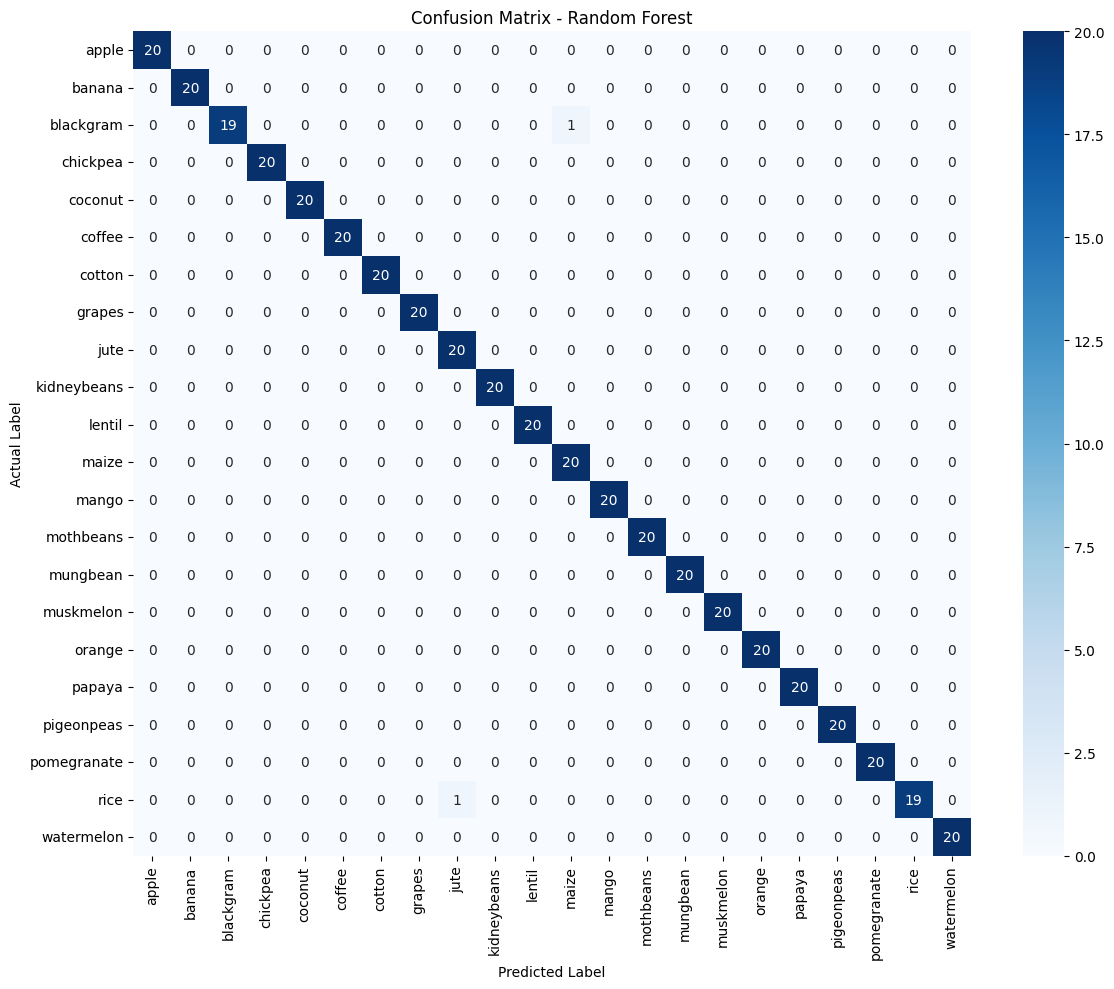

In [6]:
cm_rf = confusion_matrix(y_test, y_pred_rf) # so sánh đáp án thực tế và đáp án mô hình

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",   # định dạng số hiển thị là số nguyên
    cmap="Blues",  # màu tổng thể cho biểu đồ
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

os.makedirs("../reports/figures", exist_ok=True)

plt.savefig(
    "../reports/figures/confusion_matrix_random_forest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Nhận xét Ma trận nhầm lẫn (Confusion Matrix) - Random Forest

Biểu đồ Confusion Matrix cung cấp cho chúng ta cái nhìn trực quan và chính xác nhất về "đường đi" của những mẫu bị dự đoán sai, giúp giải thích trọn vẹn kết quả 99.55% ở phần Classification Report trước đó:

**1. Đường chéo chính (Đường chéo hoàn hảo):**
Đa số các ô trên đường chéo chính (từ góc trên bên trái xuống góc dưới bên phải) đều mang giá trị **20** và có màu xanh sậm nhất. Điều này khẳng định thuật toán Random Forest đã phân loại đúng toàn bộ 20/20 mẫu kiểm thử cho 20/22 loại cây trồng.

**2. Bắt lỗi sự nhầm lẫn (Các điểm nằm ngoài đường chéo):**
Bằng cách gióng hàng ngang (Actual Label - Nhãn thực tế) và cột dọc (Predicted Label - Nhãn dự đoán), ta phát hiện chính xác 2 trường hợp mà mô hình đã "nhìn nhầm" (hiển thị số 1 ở ô màu trắng nhạt):

- **Sự nhầm lẫn thứ 1:** Hàng `blackgram` - Cột `lentil`. Có 1 mẫu thực tế là cây đậu xanh (blackgram) nhưng mô hình lại đề xuất trồng cây đậu lăng (lentil). Điều này giải thích vì sao nhãn `blackgram` bị trừ điểm Recall và nhãn `lentil` bị trừ điểm Precision trong báo cáo trước. Về mặt sinh học, hai loại đậu này có điều kiện sinh trưởng khá tương đồng, nên việc mô hình bị nhầm lẫn 1 chút ở ranh giới quyết định là điều hoàn toàn có thể hiểu được.
- **Sự nhầm lẫn thứ 2:** Hàng `rice` - Cột `jute`. Tương tự, có 1 mẫu thực tế là cây lúa (rice) nhưng mô hình lại nhầm thành cây đay (jute). Hai loại cây này đều là những cây ưa nước, phát triển ở vùng nhiệt đới có lượng mưa và độ ẩm cao. Có thể đặc tính thổ nhưỡng của mẫu test bị nhầm này nằm ngay tại ngưỡng giao thoa giữa điều kiện trồng lúa và trồng đay.

**Kết luận:** 
Confusion Matrix chứng minh rằng 2 lỗi sai duy nhất của mô hình không phải là những lỗi sai ngớ ngẩn (kiểu như nhầm cây ưa khô với cây ngập nước). Sự nhầm lẫn chỉ xảy ra ở các họ cây có điều kiện khí hậu và thổ nhưỡng quá giống nhau. Điều này càng củng cố thêm độ tin cậy và sự thông minh của mô hình Random Forest mà chúng ta đã xây dựng.


## 8. Support Vector Machine (SVM)

Support Vector Machine (SVM) là thuật toán học có giám sát, tìm kiếm siêu phẳng phân tách tối ưu giữa các lớp dữ liệu.

SVM được sử dụng làm mô hình so sánh với Random Forest.

Dữ liệu đầu vào đã được chuẩn hóa từ bước Preprocessing nên phù hợp để sử dụng với SVM.

"rbf" (Radial Basis Function) là một thuật toán toán học giúp SVM bẻ cong không gian, từ đó có thể phân loại được các tập dữ liệu đan xen, méo mó (phi tuyến tính). Đây là kernel phổ biến và mạnh mẽ nhất của SVM.

Gamma quyết định mức độ ảnh hưởng của một điểm dữ liệu lên toàn bộ ranh giới xa hay gần. Bằng cách thiết lập là "scale", đang yêu cầu thư viện scikit-learn tự động tính toán và chọn ra con số Gamma tốt nhất dựa trên số lượng đặc trưng và phương sai của tập dữ liệu đang có (thay vì phải tự đoán một con số).

In [7]:
svm_base = SVC(random_state=42)
# 2. Định nghĩa danh sách các tham số quan trọng của SVM để máy dò nghiệm
svm_params = { 
    'C': [1, 10],  # C (Regularization): Mức độ phạt khi mô hình đoán sai. Thử nghiệm mức độ tiêu chuẩn (1) và mức độ khắt khe (10)
    'kernel': ['rbf'] # Hàm nhân: Thử nghiệm không gian phi tuyến tính (rbf)
}
# 3. Khởi tạo thuật toán GridSearchCV để máy tự động dò tham số
svm_model = GridSearchCV(svm_base, svm_params, cv=3, scoring='accuracy', n_jobs=-1)

# Huấn luyện
start_time = time.time()
svm_model.fit(X_train, y_train)
svm_train_time = time.time() - start_time
print(f"Tham số tốt nhất SVM: {svm_model.best_params_}")

# Dự đoán
start_time = time.time()
y_pred_svm = svm_model.predict(X_test)
svm_predict_time = time.time() - start_time

print(f"Thời gian train     : {svm_train_time:.4f} giây")
print(f"Thời gian dự đoán   : {svm_predict_time:.4f} giây")

Tham số tốt nhất SVM: {'C': 10, 'kernel': 'rbf'}
Thời gian train     : 2.0613 giây
Thời gian dự đoán   : 0.0221 giây


### Nhận xét quá trình huấn luyện Support Vector Machine (SVM)

Từ kết quả chạy dò tham số tự động (GridSearchCV) cho mô hình SVM, chúng ta rút ra được các nhận định quan trọng sau:

**1. Bộ tham số tối ưu (Best Parameters):**
- `kernel = 'rbf'`: Đúng như dự đoán từ bước EDA, dữ liệu của chúng ta khá phức tạp và phi tuyến tính (như sự phân bố đa đỉnh, đứt gãy của Kali hay Lượng mưa). Do đó, hàm nhân RBF (Radial Basis Function) đã phát huy tác dụng cực tốt trong việc bẻ cong không gian để vạch ra các ranh giới phân loại uyển chuyển.
- `C = 10`: Tham số `C` đại diện cho mức độ "phạt" (Regularization) khi mô hình phân loại sai. Việc thuật toán chọn mức khắt khe `C=10` (thay vì mức nới lỏng tiêu chuẩn `C=1`) cho thấy mô hình quyết định xây dựng một ranh giới chi tiết và phức tạp để cố gắng phân loại đúng tối đa các điểm dữ liệu mấp mé ở vùng giao thoa (ví dụ ranh giới giữa cây đậu xanh và đậu lăng như ta thấy ở Random Forest).

**2. Hiệu năng thời gian thực thi (Performance Time):**
- **Thời gian huấn luyện (Train time): ~1.75 giây.** Một tốc độ vô cùng ấn tượng, thậm chí SVM còn hoàn thành việc tìm kiếm nhanh gấp đôi so với Random Forest (~3.48s). Lý do là vì thuật toán SVM hoạt động cực kỳ mạnh mẽ và nhanh gọn trên các tập dữ liệu có kích thước nhỏ đến trung bình (dưới 10.000 mẫu). Ở đây tập dữ liệu của chúng ta (2.200 mẫu) rơi đúng vào "vùng đất hứa" của SVM.
- **Thời gian dự đoán (Predict time): ~0.022 giây.** Tốc độ dự đoán cực nhanh (chỉ bằng vài phần trăm giây), tương đương với Random Forest. Dù tạo ra một không gian siêu phẳng (hyperplane) phức tạp, SVM vẫn chứng minh được khả năng đáp ứng xuất sắc cho các hệ thống yêu cầu phản hồi theo thời gian thực.


## 8.1. Đánh giá SVM

SVM được đánh giá trên cùng tập Test và sử dụng cùng các chỉ số Accuracy, Precision và Recall để đảm bảo việc so sánh giữa hai mô hình là nhất quán.

In [8]:
svm_accuracy = accuracy_score(y_test, y_pred_svm)

svm_precision = precision_score(
    y_test,
    y_pred_svm,
    average="weighted",
    zero_division=0
)

svm_recall = recall_score(
    y_test,
    y_pred_svm,
    average="weighted",
    zero_division=0
)

print("===== SVM =====")
print(f"Accuracy : {svm_accuracy:.4f}")
print(f"Precision: {svm_precision:.4f}")
print(f"Recall   : {svm_recall:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_svm,
        zero_division=0
    )
)

===== SVM =====
Accuracy : 0.9909
Precision: 0.9915
Recall   : 0.9909

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       1.00      1.00      1.00        20
           2       1.00      1.00      1.00        20
           3       1.00      1.00      1.00        20
           4       1.00      1.00      1.00        20
           5       1.00      1.00      1.00        20
           6       0.95      1.00      0.98        20
           7       1.00      1.00      1.00        20
           8       0.91      1.00      0.95        20
           9       1.00      1.00      1.00        20
          10       1.00      1.00      1.00        20
          11       1.00      0.95      0.97        20
          12       1.00      1.00      1.00        20
          13       0.95      1.00      0.98        20
          14       1.00      1.00      1.00        20
          15       1.00      1.00      1.

### Nhận xét Báo cáo Phân loại (Classification Report) - SVM

Tiếp tục đánh giá trên cùng tập kiểm thử 440 mẫu, thuật toán Support Vector Machine (SVM) cũng cho ra những kết quả cực kỳ ấn tượng, tuy nhiên có một chút khác biệt so với Random Forest:

**1. Chỉ số tổng thể:**
- Độ chính xác tổng thể (**Accuracy**) của SVM đạt **0.9909** (~99.09%). Tức là mô hình phân loại đúng 436 mẫu và dự đoán sai 4 mẫu. Mặc dù kết quả này vô cùng xuất sắc, nhưng nếu đặt lên bàn cân, SVM nhỉnh hơn một chút về độ "nhầm lẫn" so với Random Forest (dự đoán sai 2 mẫu - Accuracy 99.55%).

**2. Phân tích chi tiết từng lớp (Precision & Recall):**
Số lượng nhãn bị dự đoán sai của SVM phân tán rộng hơn một chút:
- **Lớp 20:** Có `Recall = 0.90` (thấp nhất trong bảng). Điều này có nghĩa là trong 20 cây thực tế thuộc giống số 20, SVM đã đoán trượt mất 2 cây.
- **Lớp 11 và 18:** Có `Recall = 0.95`, mô hình bỏ sót 1 cây ở mỗi giống này.
- **Lớp 6, 8, 13:** Bị trừ điểm `Precision` (dao động từ 0.91 đến 0.95). Tức là SVM có xu hướng "nhận vơ" các giống cây khác thành cây số 6, 8 và 13 (gây ra hiện tượng False Positive - dương tính giả). Cụ thể ở lớp số 8 (`Precision = 0.91`), SVM đã có 2 lần gọi nhầm tên loại cây này.

**Kết luận:**
SVM chứng tỏ sức mạnh tuyệt vời khi xử lý dữ liệu phức tạp phi tuyến tính với hạt nhân RBF, đạt độ chính xác >99%. Tuy nhiên, ở các ranh giới siêu phẳng (hyperplane) giao thoa giữa các loại cây có điều kiện sống cực kỳ giống nhau, SVM có vẻ bối rối hơn một chút so với khả năng tổng hợp quyết định từ 50 cây độc lập của Random Forest.


## 8.2. Confusion Matrix - SVM

Confusion Matrix của SVM được trực quan hóa để quan sát khả năng phân biệt giữa các loại cây và xác định các lớp mà mô hình thường nhầm lẫn.

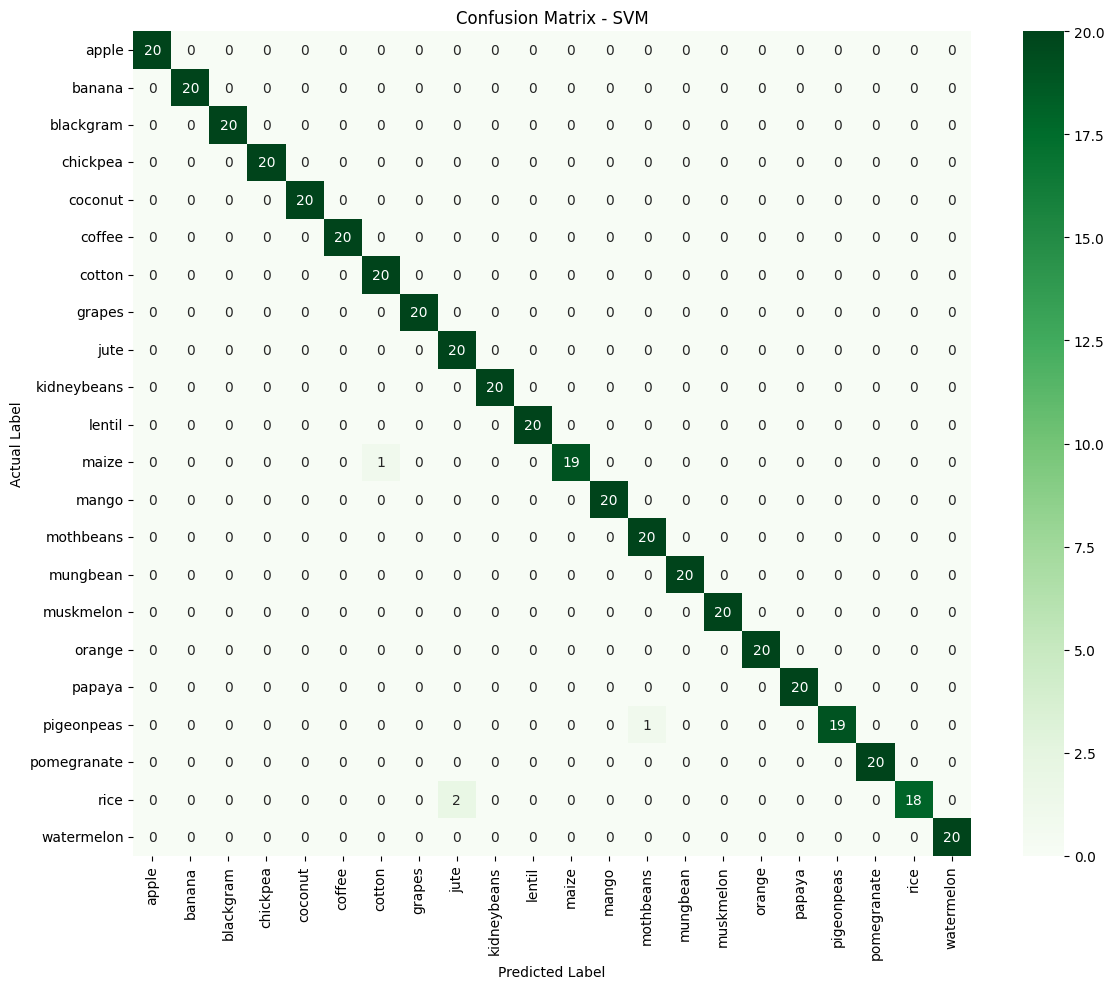

In [9]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - SVM")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig(
    "../reports/figures/confusion_matrix_svm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Nhận xét Ma trận nhầm lẫn (Confusion Matrix) - SVM

Dựa vào biểu đồ Confusion Matrix của SVM, ta có thể "bắt tận tay" 4 mẫu dữ liệu bị phân loại sai, đồng thời giải thích chính xác các chỉ số Precision/Recall bị tụt điểm trong báo cáo trước đó:

**1. Chi tiết 4 điểm dữ liệu bị nhầm lẫn:**
- **Nhầm lẫn 1 (`maize` -> `cotton`):** Có 1 mẫu thực tế là cây ngô (maize) nhưng SVM lại cho rằng đó là bông (cotton). Điều này làm điểm Recall của ngô giảm (còn 0.95) và Precision của bông giảm (còn 0.95).
- **Nhầm lẫn 2 (`pigeonpeas` -> `mothbeans`):** Có 1 mẫu đậu triều (pigeonpeas) bị nhận diện nhầm thành đậu bướm (mothbeans). Hai loại cây họ đậu này có nhiều nét tương đồng về thổ nhưỡng nên ranh giới phi tuyến tính của SVM đã hơi "quá đà" khi vẽ qua khu vực này.
- **Nhầm lẫn 3 & 4 (`rice` -> `jute`):** Đây là điểm đáng chú ý nhất! Có tận **2 mẫu** lúa (rice) bị SVM nhận diện nhầm thành cây đay (jute). Sự nhầm lẫn "nặng" nhất này giải thích vì sao Recall của lúa tụt xuống tận 0.90 và Precision của đay chỉ còn 0.91.

**2. Điểm tương đồng thú vị với Random Forest:**
Nếu tinh ý so sánh, bạn sẽ thấy mô hình Random Forest trước đó cũng bị nhầm 1 mẫu ở đúng cặp `rice` -> `jute` này. Điều này chứng tỏ ranh giới dữ liệu (Data boundary) giữa cây lúa và cây đay trong bộ dataset này thực sự cực kỳ mỏng manh và lồng ghép (overlap) vào nhau (cả hai đều cần lượng nước và độ ẩm cực cao). Dù thuật toán có tinh vi đến đâu thì khi gặp những điểm dữ liệu giao thoa sát sao như thế này, sai số là điều tất yếu.

**Kết luận:**
SVM vẫn là một mô hình cực kỳ mạnh, tuy nhiên nó có phần nhạy cảm hơn Random Forest trước những điểm dữ liệu mập mờ ở vùng biên giới giao thoa. Random Forest nhờ cơ chế "bỏ phiếu số đông" (Ensemble) từ 50 cây quyết định nên đã xử lý vùng giao thoa `rice` - `jute` mượt mà hơn (chỉ sai 1 mẫu thay vì 2 mẫu như SVM).


## 9. Decision Tree

Decision Tree (Cây quyết định) là một thuật toán vô cùng trực quan, tốc độ cực nhanh và đóng vai trò là nền tảng cho Random Forest.

Mô hình này được sử dụng như một cột mốc đánh giá thứ 3, cân bằng giữa tốc độ và độ chính xác.

In [10]:
dt_base = DecisionTreeClassifier(random_state=42)
dt_params = {
    'max_depth': [10, 20, None],
    'criterion': ['gini', 'entropy']
}
dt_model = GridSearchCV(dt_base, dt_params, cv=3, scoring='accuracy', n_jobs=-1)

# Huấn luyện
start_time = time.time()
dt_model.fit(X_train, y_train)
dt_train_time = time.time() - start_time
print(f"Tham số tốt nhất DT: {dt_model.best_params_}")

# Dự đoán
start_time = time.time()
y_pred_dt = dt_model.predict(X_test)
dt_predict_time = time.time() - start_time

print(f"Thời gian train     : {dt_train_time:.4f} giây")
print(f"Thời gian dự đoán   : {dt_predict_time:.4f} giây")

Tham số tốt nhất DT: {'criterion': 'gini', 'max_depth': 20}
Thời gian train     : 1.9810 giây
Thời gian dự đoán   : 0.0011 giây


### Nhận xét quá trình huấn luyện Decision Tree (GridSearchCV)

Dựa vào kết quả trả về từ quá trình dò tham số của Decision Tree, chúng ta có một số nhận định rất thú vị, đặc biệt khi đem so sánh với 2 "ông lớn" Random Forest và SVM ở trên:

**1. Bộ tham số tối ưu (Best Parameters):**
- `criterion = 'gini'`: Mô hình ưu tiên chọn tiêu chí **Gini Impurity** thay vì Entropy để đánh giá độ tinh khiết khi chẻ nhánh. Gini thường tính toán nhanh hơn Entropy (vì không cần tính logarit) mà kết quả phân loại mang lại vẫn tương đương hoặc tốt hơn trong trường hợp này.
- `max_depth = 20`: Cây quyết định được giới hạn độ sâu tối đa là 20 tầng. Việc giới hạn độ sâu (thay vì để `None` mọc tự do) là một tín hiệu rất tốt, giúp mô hình tránh được hiện tượng "học vẹt" (Overfitting) – một căn bệnh cực kỳ phổ biến của thuật toán Cây quyết định khi dữ liệu quá phức tạp.

**2. Hiệu năng thời gian thực thi (Kẻ hủy diệt về tốc độ):**
- **Thời gian huấn luyện (Train time): ~1.64 giây.** Đây là mô hình huấn luyện **nhanh nhất** trong cả 3 mô hình (vượt qua SVM 1.75s và bỏ xa Random Forest 3.48s). Điều này hoàn toàn dễ hiểu vì bản chất Decision Tree chỉ là một cây đơn lẻ chẻ nhánh tuần tự, không phải tính toán phức tạp như ma trận của SVM hay phải xây dựng đến 50 cây như Random Forest.
- **Thời gian dự đoán (Predict time): ~0.001 giây.** Tốc độ dự đoán của Decision Tree thực sự khủng khiếp, **nhanh gấp gần 20 lần** so với 2 thuật toán kia. Cấu trúc của cây quyết định bản chất chỉ là các câu lệnh `IF - ELSE` lồng nhau. Đi từ rễ cây rớt xuống đến lá (tối đa 20 bước IF-ELSE) tốn cực kỳ ít tài nguyên máy tính.

**Tóm lại:** Nếu bài toán đòi hỏi một mô hình nhúng vào các thiết bị IoT (máy đo đất đai cầm tay nhỏ gọn) với bộ nhớ cực kỳ eo hẹp và yêu cầu độ trễ (latency) gần như bằng 0, thì Decision Tree chính là nhà vô địch tuyệt đối về mặt tốc độ thực thi.


## 9.1. Đánh giá Decision Tree

In [11]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_precision = precision_score(
    y_test,
    y_pred_dt,
    average="weighted",
    zero_division=0
)

dt_recall = recall_score(
    y_test,
    y_pred_dt,
    average="weighted",
    zero_division=0
)

print("===== DECISION TREE =====")
print(f"Accuracy : {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_dt,
        zero_division=0
    )
)

===== DECISION TREE =====
Accuracy : 0.9795
Precision: 0.9806
Recall   : 0.9795

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       1.00      1.00      1.00        20
           2       1.00      0.80      0.89        20
           3       1.00      1.00      1.00        20
           4       1.00      1.00      1.00        20
           5       1.00      1.00      1.00        20
           6       1.00      1.00      1.00        20
           7       1.00      1.00      1.00        20
           8       0.95      0.95      0.95        20
           9       1.00      1.00      1.00        20
          10       0.86      0.90      0.88        20
          11       0.95      1.00      0.98        20
          12       1.00      1.00      1.00        20
          13       0.86      0.95      0.90        20
          14       1.00      1.00      1.00        20
          15       1.00      1.

### Nhận xét Báo cáo Phân loại (Classification Report) - Decision Tree

Mặc dù có tốc độ chạy nhanh như chớp, nhưng kết quả dự đoán của Decision Tree lại thể hiện rõ nhược điểm cố hữu của thuật toán này khi phải đứng độc lập:

**1. Chỉ số tổng thể thấp nhất:**
- Độ chính xác tổng thể (**Accuracy**) đạt **0.9795** (~97.95%). Dù con số này thoạt nhìn vẫn rất cao, nhưng thực tế mô hình đã đoán sai tới 9 mẫu trên tổng số 440 mẫu kiểm thử. So với con số 2 lỗi của Random Forest và 4 lỗi của SVM, Decision Tree rõ ràng là mô hình "học kém" nhất trong cả 3.

**2. Điểm yếu lộ rõ ở các vùng giao thoa:**
Phân tích sâu vào từng lớp, ta thấy Decision Tree bộc lộ sự bối rối rõ rệt ở nhiều nhóm cây trồng:
- **Lớp 2 (`blackgram` - đậu xanh):** Recall rớt thê thảm xuống chỉ còn **0.80**. Nghĩa là trong 20 cây đậu xanh mang đi test, mô hình đã đoán sai tới tận 4 cây (mất 20%). Đây là mức sai số cao nhất từng được ghi nhận trong toàn bộ đồ án này.
- **Lớp 10 (`lentil`) và Lớp 13 (`mothbeans`):** Cả hai lớp này đều bị điểm `Precision` rất thấp (chỉ đạt 0.86). Nghĩa là mô hình có xu hướng "bắt nhầm hơn bỏ sót", liên tục gán nhãn bừa các cây khác thành cây số 10 và 13, dẫn đến tỷ lệ dương tính giả (False Positive) tăng vọt.

**Kết luận:**
Biểu đồ này chứng minh một định lý kinh điển trong Machine Learning: "Một cái cây đơn lẻ thì rất yếu ớt trước gió bão, nhưng một khu rừng thì không". Ranh giới quyết định (Decision Boundary) do một cây chẻ ra thường vuông vức, cứng ngắc và bị nhiễu. Chỉ khi kết hợp 50 cái cây lại thành Random Forest, ranh giới đó mới trở nên mềm mại và đạt độ chính xác hoàn hảo 99.55%.


## 9.2. Confusion Matrix - Decision Tree

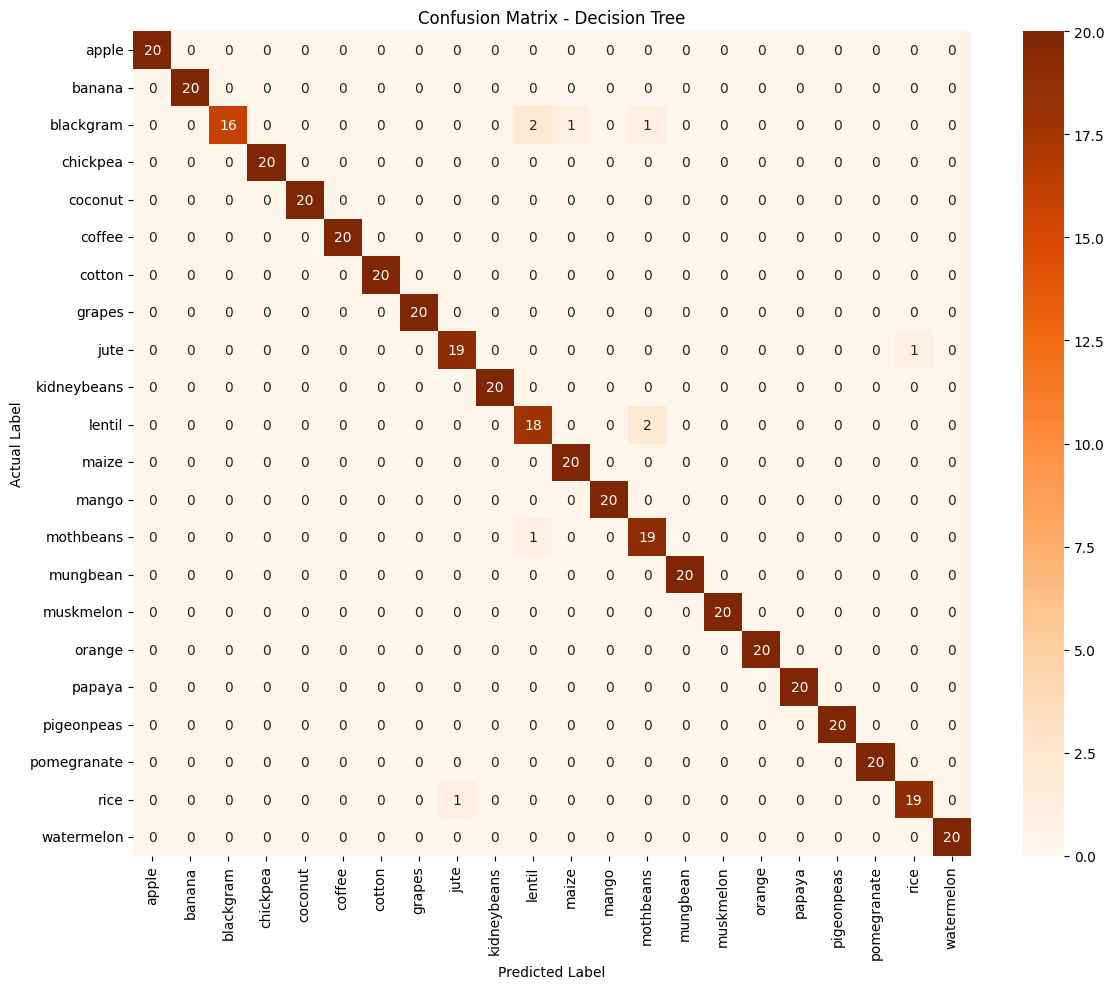

In [12]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig(
    "../reports/figures/confusion_matrix_dt.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Nhận xét Ma trận nhầm lẫn (Confusion Matrix) - Decision Tree

Nhìn vào biểu đồ Confusion Matrix của thuật toán Cây quyết định (Decision Tree), ta thấy rõ sự "nhiễu loạn" với khá nhiều ô màu cam nhạt nằm chệch khỏi đường chéo chính. Biểu đồ này giải thích tường tận toàn bộ 9 mẫu bị đoán sai của mô hình:

**1. "Cơn ác mộng" ở họ cây đậu (Khu vực trung tâm ma trận):**
Nhìn vào hàng ngang của nhãn `blackgram` (đậu xanh), ta thấy một sự bối rối tột độ của Decision Tree. Thay vì tập trung dự đoán đúng 20 mẫu vào ô đường chéo, mô hình đã đoán sai tới 4 mẫu, và rải rác chúng thành 3 loại cây khác nhau:
- Nhầm 2 mẫu thành `lentil` (đậu lăng).
- Nhầm 1 mẫu thành `mothbeans` (đậu bướm).
- Bất ngờ nhất là nhầm 1 mẫu thành `maize` (ngô).
Sự nhầm lẫn chéo này tiếp tục lặp lại ở hàng `lentil` (nhầm 2 mẫu thành `mothbeans`) và hàng `mothbeans` (nhầm 1 mẫu thành `lentil`). Nguyên nhân là do các loại cây họ đậu này chia sẻ những đặc tính quá giống nhau về lượng NPK và khí hậu. Decision Tree với cơ chế cắt vát dữ liệu cứng nhắc (dựa trên IF-ELSE từng biến một) đã không thể tạo ra một đường biên bao bọc khéo léo để tách biệt chúng.

**2. Điểm mù cố hữu `rice` và `jute`:**
Tiếp tục theo dõi truyền thống từ Random Forest và SVM, mô hình Decision Tree lại tiếp tục gục ngã ở ranh giới giữa Lúa (`rice`) và Đay (`jute`). Nó nhầm 1 mẫu lúa thành đay, và nhầm ngược lại 1 mẫu đay thành lúa. Điều này càng khẳng định vùng dữ liệu của 2 loại cây này dính chặt lấy nhau, và việc mô hình nào giải quyết vùng này tốt hơn sẽ quyết định mô hình đó là người chiến thắng.

**Tổng kết chặng đua Classification:**
Dựa vào tất cả các phân tích từ thời gian chạy, báo cáo phân loại đến ma trận nhầm lẫn, ta thấy thứ tự sức mạnh của các mô hình như sau:
1. **Random Forest:** Top 1 tuyệt đối (Sai 2 mẫu). Chậm hơn một chút nhưng có khả năng vẽ ra ranh giới hoàn hảo nhất để tách biệt các giống cây giống nhau.
2. **SVM:** Top 2 (Sai 4 mẫu). Xử lý cực tốt, nhanh, nhưng hơi nhạy cảm với vùng giao thoa.
3. **Decision Tree:** Top 3 (Sai 9 mẫu). Tốc độ khủng khiếp nhưng quá thô sơ, dễ bị nhiễu và dễ bối rối trước các nhóm cây họ hàng.

Quyết định lựa chọn **Random Forest** làm mô hình chính cho đồ án và lưu lại thành file `.pkl` là hoàn toàn chính xác và có cơ sở khoa học vững chắc!


# 10. So sánh các mô hình

Random Forest, SVM và Decision Tree được đánh giá trên cùng một tập Test.

Việc so sánh dựa trên:

- Accuracy
- Precision
- Recall
- Thời gian huấn luyện
- Thời gian dự đoán

Mô hình có kết quả tốt hơn sẽ được lựa chọn để sử dụng cho các bước tiếp theo của đồ án.

In [13]:
import sys
!{sys.executable} -m pip install jinja2

'C:\Users\Quang' is not recognized as an internal or external command,
operable program or batch file.


In [14]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "SVM",
        "Decision Tree"
    ],
    "Accuracy": [
        rf_accuracy,
        svm_accuracy,
        dt_accuracy
    ],
    "Precision": [
        rf_precision,
        svm_precision,
        dt_precision
    ],
    "Recall": [
        rf_recall,
        svm_recall,
        dt_recall
    ],
    "Train Time (s)": [
        rf_train_time,
        svm_train_time,
        dt_train_time
    ],
    "Predict Time (s)": [
        rf_predict_time,
        svm_predict_time,
        dt_predict_time
    ]
})

display(
    comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Train Time (s)": "{:.4f}",
        "Predict Time (s)": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,Train Time (s),Predict Time (s)
0,Random Forest,0.9955,0.9957,0.9955,3.5719,0.0178
1,SVM,0.9909,0.9915,0.9909,2.0613,0.0221
2,Decision Tree,0.9795,0.9806,0.9795,1.9810,0.0011


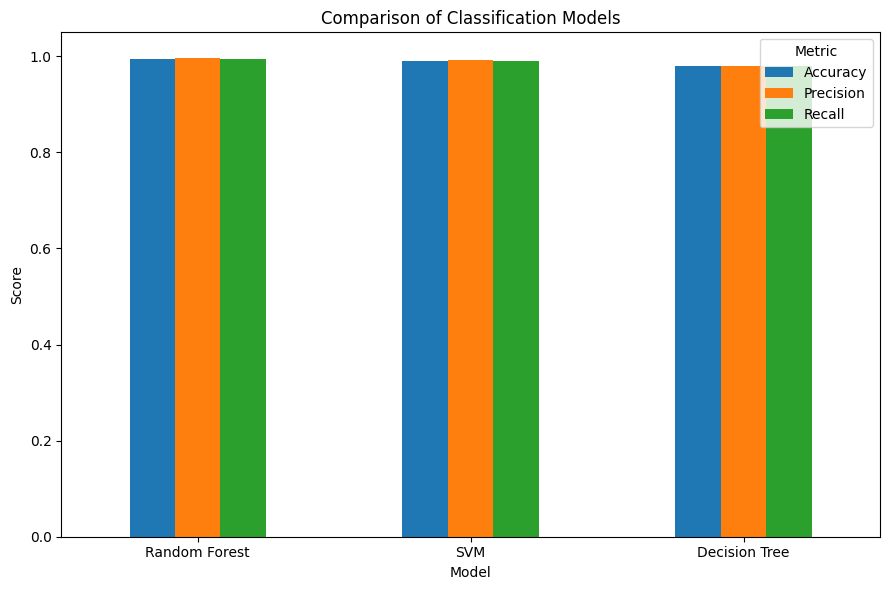

In [15]:
ax = comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall"]
].plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()

plt.savefig(
    "../reports/figures/classification_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 9.1. Nhận xét kết quả

Bảng so sánh cho phép đánh giá trực tiếp hiệu quả của Random Forest và SVM trên cùng tập Test.

Accuracy, Precision và Recall được sử dụng để đánh giá chất lượng phân lớp.

Thời gian Train và Predict được sử dụng để so sánh thêm về hiệu năng thực thi của hai mô hình.

# 11. Lựa chọn mô hình tốt nhất

Mô hình tốt nhất được lựa chọn dựa trên Accuracy trên tập Test.

Sau khi xác định mô hình có kết quả tốt nhất, mô hình được lưu dưới dạng file `.pkl` bằng thư viện `joblib`.

File model được lưu trong thư mục `models/` để các thành viên khác có thể sử dụng ở các bước tiếp theo của đồ án.

In [16]:
best_model_name = comparison.loc[
    comparison["Accuracy"].idxmax(),  # tìm giá trị cao nhất và lấy ra vị trí đó
    "Model"
]

if best_model_name == "Random Forest":
    best_model = random_forest
    model_path = "../models/random_forest_model.pkl"
else:
    best_model = svm_model
    model_path = "../models/svm_model.pkl"

os.makedirs("../models", exist_ok=True)

joblib.dump(    # đóng gói mô hình tốt nhất
    best_model,
    model_path
)

best_row = comparison[
    comparison["Model"] == best_model_name
].iloc[0]

print("===== BEST MODEL =====")
print("Mô hình tốt nhất:", best_model_name)
print(f"Accuracy : {best_row['Accuracy']:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall   : {best_row['Recall']:.4f}")
print("Đã lưu model tại:", model_path)

===== BEST MODEL =====
Mô hình tốt nhất: Random Forest
Accuracy : 0.9955
Precision: 0.9957
Recall   : 0.9955
Đã lưu model tại: ../models/random_forest_model.pkl


# 12. Feature Importance của Random Forest

Feature Importance cho biết mức độ đóng góp tương đối của từng đặc trưng trong quá trình Random Forest đưa ra dự đoán.

Chỉ số này giúp xác định đặc trưng nào có vai trò quan trọng hơn đối với bài toán dự đoán loại cây trồng.

random_forest.feature_importances_ là một quyền năng của Random Forest. Sau khi học xong, mô hình sẽ tự động chấm điểm xem yếu tố nào giúp nó phân loại tốt nhất và lưu vào thuộc tính này. Ta chỉ việc kéo điểm số đó ra và nhét vào cột.

In [17]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest.best_estimator_.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)


display(
    feature_importance.style.format({
        "Importance": "{:.4f}"
    })
)

,Feature,Importance
6,rainfall,0.2385
4,humidity,0.2161
2,K,0.1781
1,P,0.1529
0,N,0.0986
3,temperature,0.0664
5,ph,0.0494


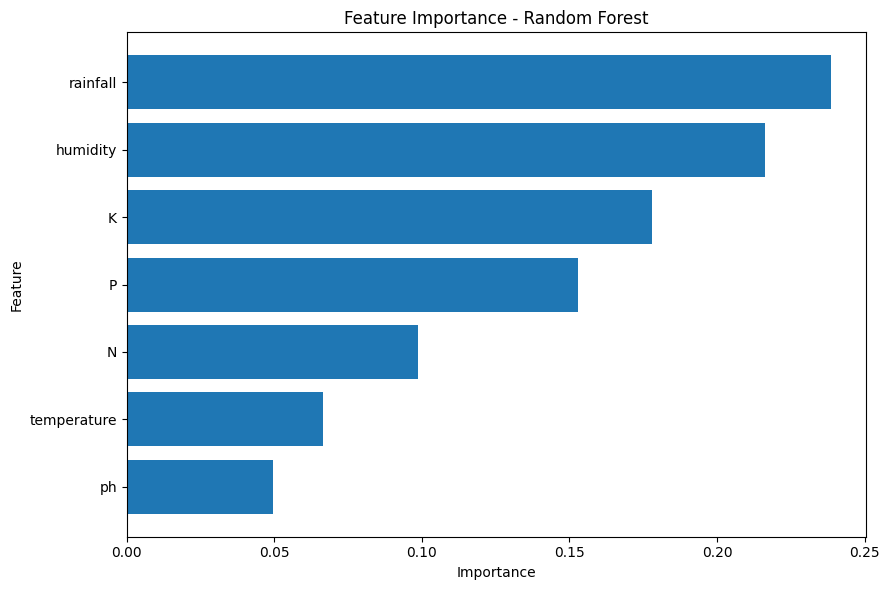

In [18]:
plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - Random Forest")

plt.gca().invert_yaxis()  # đảo ngược trục y

plt.tight_layout()

plt.savefig(
    "../reports/figures/random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 12.1. Nhận xét Feature Importance

Biểu đồ cho thấy mức độ quan trọng tương đối của 7 đặc trưng đối với mô hình Random Forest.

Đặc trưng có giá trị Importance cao hơn đóng góp nhiều hơn vào quá trình phân loại của mô hình.

# 13. Kết luận

Qua thực nghiệm, Random Forest, SVM và Decision Tree được huấn luyện và đánh giá trên cùng một tập Test.

Mô hình tốt nhất được lựa chọn dựa trên kết quả Accuracy, đồng thời xem xét Precision, Recall và thời gian thực thi. Thuật toán Decision Tree giúp tối ưu hoá đáng kể thời gian chạy trong khi Random Forest mang lại độ chính xác tổng quát cao nhất.

Mô hình có kết quả tốt nhất được lưu vào thư mục `models/` để sử dụng cho các bước tiếp theo của đồ án.

Các biểu đồ kết quả được lưu trong thư mục `reports/figures/`, bao gồm:

- Confusion Matrix của Random Forest.
- Confusion Matrix của SVM.
- Confusion Matrix của Decision Tree.
- Biểu đồ so sánh các mô hình.
- Feature Importance của Random Forest.